# 01 – Khám phá & kiểm chứng dữ liệu đa kênh

Nội dung 2 (thuyết minh): khảo sát dữ liệu đơn hàng sau làm sạch, kiểm chứng các bước tiền xử lý và phân tích mô tả.

> **Quyền riêng tư:** `customer_id` được dựng từ số điện thoại khách hàng. Notebook chỉ hiển thị số liệu tổng hợp hoặc mã đã che (`KH_0908***444`). Không in trực tiếp cột `customer_id` / `bill_phone_number` / `bill_full_name`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # bảng màu đã kiểm định CVD
from backend.ml import feature_engineering as fe
from backend.app.core.customer_store import mask_customer_id  # che số điện thoại khi hiển thị

## 1. Nạp dữ liệu đơn hàng đã làm sạch
`fe.load_orders()` đọc `Cleaned_data/orders_cleaned.csv` và chuẩn hóa thời gian, kênh, vùng (cùng hàm dùng trong pipeline huấn luyện).

In [2]:
orders = fe.load_orders()
print(f"{len(orders):,} đơn | {orders['customer_id'].nunique():,} khách | {orders.shape[1]} cột")
print("Thời gian:", orders["order_time"].min(), "→", orders["order_time"].max())
print("Số ô thiếu dữ liệu:", int(orders.isna().sum().sum()))

21,249 đơn | 19,100 khách | 55 cột
Thời gian: 2022-06-11 17:44:31 → 2022-11-11 10:59:44
Số ô thiếu dữ liệu: 0


In [3]:
# Kiểu dữ liệu & ví dụ giá trị (không gồm cột định danh cá nhân)
PII_COLS = ["customer_id", "bill_phone_number", "bill_full_name"]
info = pd.DataFrame({"dtype": orders.dtypes.astype(str), "n_unique": orders.nunique()}).drop(index=PII_COLS)
info.head(25)

,dtype,n_unique
id,int64,21249
order_id,int64,21249
shop_id,int64,1
page_id,int64,42
total_price,int64,501
status,int64,9
product_id,str,231
quantity,float64,18
province_id,int64,35
district_id,int64,683


## 2. Kiểm chứng các bước làm sạch
Các cột cờ / cắt ngưỡng / ánh xạ trong dữ liệu sau làm sạch cho biết các bước tiền xử lý đã áp dụng (Bảng 4.3 của báo cáo).

In [4]:
checks = {
    "Đơn COD âm (is_negative_cod)": int(orders["is_negative_cod"].sum()),
    "Đơn quà tặng / 0 đồng (is_gift_or_free)": int(orders["is_gift_or_free"].sum()),
    "Đơn dùng chung số điện thoại (is_shared_phone)": int(orders["is_shared_phone"].sum()),
    "Đơn vượt trần giá (total_price_cleaned > total_price_capped)": int((orders["total_price_cleaned"] > orders["total_price_capped"]).sum()),
    "Trần giá trị đơn (VNĐ)": float(orders["total_price_capped"].max()),
    "Trần số lượng": float(orders["quantity_capped"].max()),
    "Số trạng thái gốc → nhóm": f'{orders["status_name"].nunique()} → {orders["status_group"].nunique()}',
    "Số nguồn bán → nhóm kênh": f'{orders["source"].nunique()} → {orders["channel_group"].nunique()}',
}
pd.Series(checks, name="Giá trị").to_frame()

,Giá trị
Đơn COD âm (is_negative_cod),33
Đơn quà tặng / 0 đồng (is_gift_or_free),26
Đơn dùng chung số điện thoại (is_shared_phone),296
Đơn vượt trần giá (total_price_cleaned > total_price_capped),212
Trần giá trị đơn (VNĐ),760000.0
Trần số lượng,4.0
Số trạng thái gốc → nhóm,9 → 4
Số nguồn bán → nhóm kênh,44 → 5


In [5]:
pd.crosstab(orders["status_name"], orders["status_group"])

status_group,Cancelled,Completed,In_Progress,Returned
status_name,,,,
Chờ chuyển hàng,0,0,584,0
Chờ hàng,0,0,628,0
Huỷ đơn hàng,573,0,0,0
Mới,0,0,112,0
Trả hàng thành công,0,0,0,1193
Đang trả hàng,0,0,0,197
Đã gửi,0,0,1806,2
Đã nhận,0,16111,0,0
Đã xác nhận,0,0,43,0


## 3. Phân bổ theo kênh và vùng miền

In [6]:
def share_table(col):
    g = orders.groupby(col).agg(don=("order_id", "nunique"), khach=("customer_id", "nunique"),
                               ty_le_hoan=("is_returned", "mean"),
                               ty_le_huy=("status_group", lambda s: (s == "Cancelled").mean()))
    g["ty_trong_don"] = g["don"] / g["don"].sum()
    return g.sort_values("don", ascending=False)

ch = share_table("channel_group"); rg = share_table("region_type")
display(ch.style.format({"ty_le_hoan": "{:.1%}", "ty_le_huy": "{:.1%}", "ty_trong_don": "{:.1%}"}))
display(rg.style.format({"ty_le_hoan": "{:.1%}", "ty_le_huy": "{:.1%}", "ty_trong_don": "{:.1%}"}))

,don,khach,ty_le_hoan,ty_le_huy,ty_trong_don
channel_group,,,,,
Facebook Fanpage,19283,17515,6.6%,2.6%,90.7%
Unknown/Other,795,652,3.8%,3.0%,3.7%
Website,711,680,10.1%,5.5%,3.3%
TikTok Shop,444,420,3.6%,1.1%,2.1%
Shopee,16,15,0.0%,6.2%,0.1%


,don,khach,ty_le_hoan,ty_le_huy,ty_trong_don
region_type,,,,,
Miền Nam,15516,13862,5.9%,2.6%,73.0%
Miền Trung,3132,2838,7.6%,2.6%,14.7%
Miền Bắc,2600,2421,9.1%,3.3%,12.2%
Chưa xác định,1,1,0.0%,100.0%,0.0%


Khách mua trên >= 2 kênh: 181


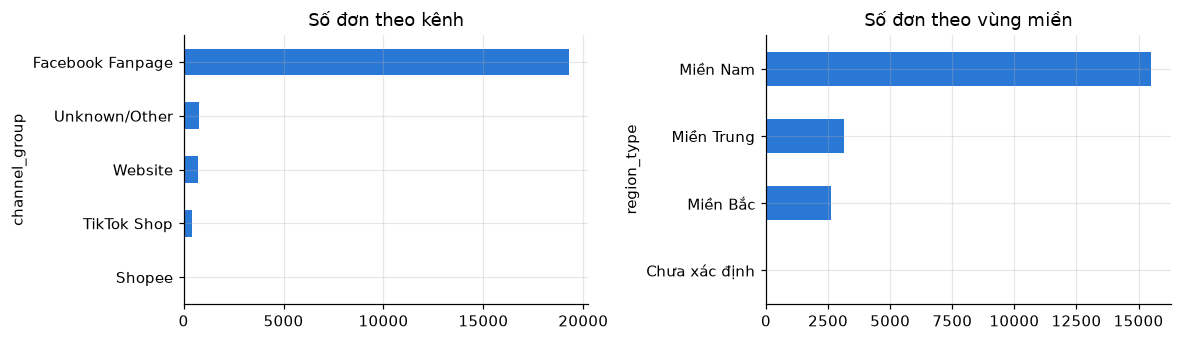

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
ch["don"][::-1].plot.barh(ax=axes[0], color=C[0]); axes[0].set_title("Số đơn theo kênh")
rg["don"][::-1].plot.barh(ax=axes[1], color=C[0]); axes[1].set_title("Số đơn theo vùng miền")
plt.tight_layout()
print("Khách mua trên >= 2 kênh:", int((orders.groupby("customer_id")["channel_group"].nunique() >= 2).sum()))

## 4. Xu hướng theo thời gian

Tỷ trọng đơn tháng 10–11/2022: 99.4%


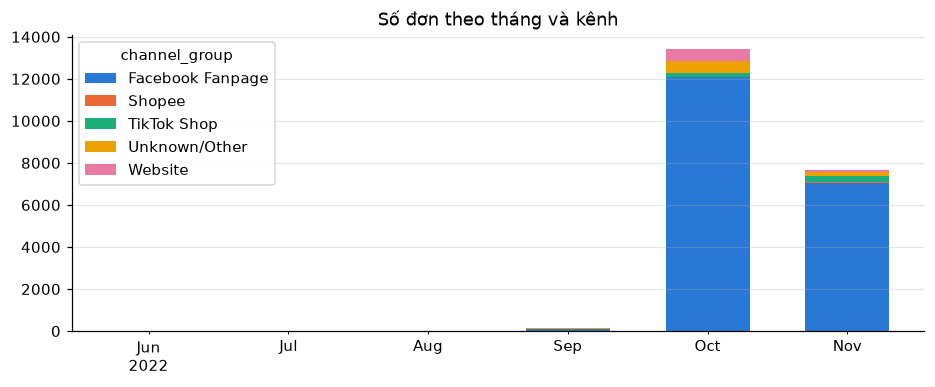

In [8]:
monthly = orders.pivot_table(index=orders["order_time"].dt.to_period("M"), columns="channel_group", values="order_id", aggfunc="count", fill_value=0)
ax = monthly.plot.bar(stacked=True, figsize=(10, 3.5), color=C[:monthly.shape[1]], width=0.6)
ax.set_title("Số đơn theo tháng và kênh"); ax.set_xlabel("")
print(f"Tỷ trọng đơn tháng 10–11/2022: {monthly.loc['2022-10':'2022-11'].values.sum() / len(orders):.1%}")

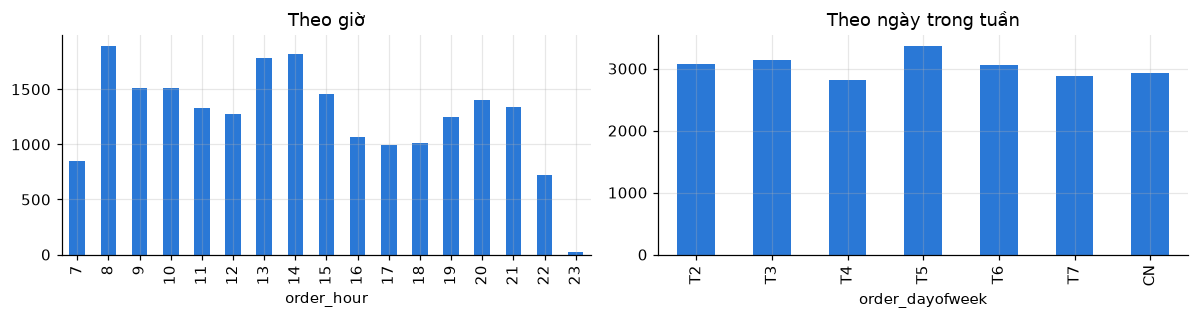

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3))
orders["order_hour"].value_counts().sort_index().plot.bar(ax=axes[0], color=C[0]); axes[0].set_title("Theo giờ")
orders["order_dayofweek"].value_counts().sort_index().rename(index=dict(enumerate(["T2","T3","T4","T5","T6","T7","CN"]))).plot.bar(ax=axes[1], color=C[0]); axes[1].set_title("Theo ngày trong tuần")
plt.tight_layout()

## 5. Trạng thái đơn, giá trị đơn và tần suất mua

,tỷ lệ
status_group,
Completed,75.8%
In_Progress,14.9%
Returned,6.6%
Cancelled,2.7%


count      21249.0
mean      321035.0
std       134288.0
min            0.0
25%       260000.0
50%       300000.0
75%       380000.0
max      4000000.0
Name: total_price_cleaned, dtype: float64


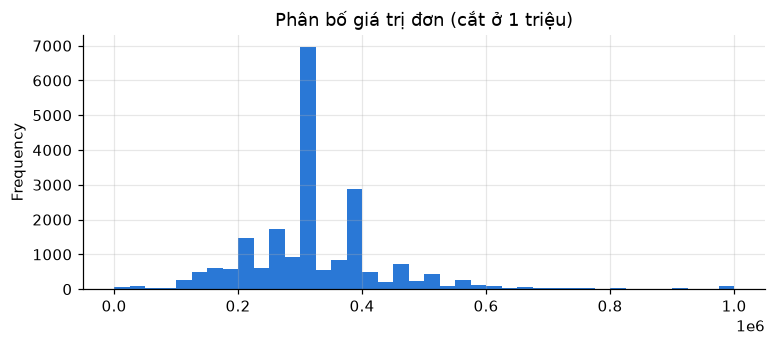

In [10]:
display(orders["status_group"].value_counts(normalize=True).rename("tỷ lệ").to_frame().style.format("{:.1%}"))
print(orders["total_price_cleaned"].describe().round(0))
orders["total_price_cleaned"].clip(upper=1_000_000).plot.hist(bins=40, color=C[0], figsize=(8, 3), title="Phân bố giá trị đơn (cắt ở 1 triệu)");

In [11]:
rfm = fe.read_csv("customer_rfm_features.csv")
freq = rfm["completed_orders"].clip(upper=4).value_counts(normalize=True).sort_index()
freq.index = [str(i) if i < 4 else ">=4" for i in freq.index]
display(freq.rename("tỷ lệ khách").to_frame().style.format("{:.1%}"))
print(f"Khách mua thành công >= 2 lần: {(rfm['completed_orders'] >= 2).sum():,} ({(rfm['completed_orders'] >= 2).mean():.1%})")

,tỷ lệ khách
0,22.1%
1,72.3%
2,5.1%
3,0.5%
>=4,0.1%


Khách mua thành công >= 2 lần: 1,082 (5.7%)


## 6. Nhận xét
- Dữ liệu tập trung ở kênh Facebook Fanpage và miền Nam; các kênh nhỏ (Shopee) quá ít mẫu để phân tích riêng.
- Lịch sử mua ngắn: phần lớn đơn phát sinh trong tháng 10–11/2022; tỷ lệ khách mua lại rất thấp.
- Hai đặc điểm này quyết định cách định nghĩa bài toán rời bỏ (notebook 02) và cách phân cụm (notebook 03).